In [ ]:
from pathlib import Path
from PIL import Image

In [5]:
# 当前 Jupyter 工作目录
current_dir = Path.cwd()

# 寻找项目根目录

project_root = current_dir.parent
data_root = project_root / "data"

div2k_train = data_root / "DIV2K_train_HR"
div2k_valid = data_root / "DIV2K_valid_HR"
sidd_root = data_root / "SIDD_Medium_Srgb" / "Data"

print("项目根目录：", project_root)
print("DIV2K训练集：", div2k_train)
print("DIV2K验证集：", div2k_valid)
print("SIDD数据目录：", sidd_root)

项目根目录： d:\CodeRepository\graduation‑design
DIV2K训练集： d:\CodeRepository\graduation‑design\data\DIV2K_train_HR
DIV2K验证集： d:\CodeRepository\graduation‑design\data\DIV2K_valid_HR
SIDD数据目录： d:\CodeRepository\graduation‑design\data\SIDD_Medium_Srgb\Data


In [11]:
train_images = list(div2k_train.glob("*.png"))
valid_images = sorted(div2k_valid.glob("*.png"))

print("DIV2K Train 图片数量：", len(train_images))
print("DIV2K Valid 图片数量：", len(valid_images))

print("Train 数量是否为 800：", len(train_images) == 800)
print("Valid 数量是否为 100：", len(valid_images) == 100)

DIV2K Train 图片数量： 800
DIV2K Valid 图片数量： 100
Train 数量是否为 800： True
Valid 数量是否为 100： True


In [14]:
all_div2k_images = train_images + valid_images
print(f"{all_div2k_images}")
print(f"{len(all_div2k_images)}")
print(f"{type(all_div2k_images)}")


[WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0001.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0002.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0003.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0004.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0005.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0006.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0007.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0008.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0009.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0010.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0011.png'), WindowsPath('d:/CodeRepository/graduation‑design/data/DIV2K_train_HR/0012.png'), WindowsPath('d:/CodeReposit

In [15]:
div2k_errors = []

all_div2k_images = train_images + valid_images

for image_path in all_div2k_images:
    try:
        with Image.open(image_path) as img:
            img.load()

            if img.mode != "RGB":
                div2k_errors.append(
                    (image_path, f"通道模式异常：{img.mode}")
                )

    except Exception as e:
        div2k_errors.append(
            (image_path, f"读取失败：{e}")
        )

print("检查图片数量：", len(all_div2k_images))
print("异常数量：", len(div2k_errors))

if div2k_errors:
    for error in div2k_errors:
        print(error)
else:
    print("DIV2K 检查通过")

检查图片数量： 900
异常数量： 0
DIV2K 检查通过


In [16]:
scene_dirs = sorted([
    path for path in sidd_root.iterdir()
    if path.is_dir()
])

noisy_files = sorted(sidd_root.rglob("*_NOISY_SRGB_*.PNG"))
gt_files = sorted(sidd_root.rglob("*_GT_SRGB_*.PNG"))

print("Scene Instance 目录数量：", len(scene_dirs))
print("NOISY 图片数量：", len(noisy_files))
print("GT 图片数量：", len(gt_files))

print()
print("Scene Instance 是否为 160：", len(scene_dirs) == 160)
print("NOISY 是否为 320：", len(noisy_files) == 320)
print("GT 是否为 320：", len(gt_files) == 320)

Scene Instance 目录数量： 160
NOISY 图片数量： 320
GT 图片数量： 320

Scene Instance 是否为 160： True
NOISY 是否为 320： True
GT 是否为 320： True


In [17]:
scene_errors = []

for scene_dir in scene_dirs:
    noisy = list(scene_dir.glob("*_NOISY_SRGB_*.PNG"))
    gt = list(scene_dir.glob("*_GT_SRGB_*.PNG"))

    if len(noisy) != 2 or len(gt) != 2:
        scene_errors.append(
            (
                scene_dir.name,
                len(noisy),
                len(gt)
            )
        )

print("检查 Scene Instance 数量：", len(scene_dirs))
print("异常 Scene Instance 数量：", len(scene_errors))

if scene_errors:
    for scene_name, noisy_count, gt_count in scene_errors:
        print(
            scene_name,
            "NOISY =", noisy_count,
            "GT =", gt_count
        )
else:
    print("所有 Scene Instance 文件数量正常")

检查 Scene Instance 数量： 160
异常 Scene Instance 数量： 0
所有 Scene Instance 文件数量正常


In [18]:
pair_errors = []
valid_pairs = 0

for noisy_path in noisy_files:

    # 根据 NOISY 文件名推导对应的 GT 文件名
    gt_name = noisy_path.name.replace(
        "_NOISY_SRGB_",
        "_GT_SRGB_"
    )

    gt_path = noisy_path.parent / gt_name

    # 检查 GT 是否存在
    if not gt_path.exists():
        pair_errors.append(
            (noisy_path, "找不到对应 GT")
        )
        continue

    try:
        with Image.open(noisy_path) as noisy_img, \
             Image.open(gt_path) as gt_img:

            noisy_img.load()
            gt_img.load()

            # 检查尺寸
            if noisy_img.size != gt_img.size:
                pair_errors.append(
                    (
                        noisy_path,
                        f"尺寸不一致："
                        f"NOISY={noisy_img.size}, "
                        f"GT={gt_img.size}"
                    )
                )
                continue

            # 检查 RGB
            if noisy_img.mode != "RGB":
                pair_errors.append(
                    (
                        noisy_path,
                        f"NOISY不是RGB：{noisy_img.mode}"
                    )
                )
                continue

            if gt_img.mode != "RGB":
                pair_errors.append(
                    (
                        gt_path,
                        f"GT不是RGB：{gt_img.mode}"
                    )
                )
                continue

            valid_pairs += 1

    except Exception as e:
        pair_errors.append(
            (noisy_path, f"图片读取失败：{e}")
        )

print("NOISY 总数：", len(noisy_files))
print("有效配对数量：", valid_pairs)
print("异常数量：", len(pair_errors))

if pair_errors:
    print("\n异常文件：")

    for path, reason in pair_errors:
        print(path)
        print("原因：", reason)
        print()
else:
    print("SIDD 所有 NOISY / GT 配对检查通过")

NOISY 总数： 320
有效配对数量： 320
异常数量： 0
SIDD 所有 NOISY / GT 配对检查通过


In [19]:
print("=" * 50)
print("数据集检查结果")
print("=" * 50)

print("\nDIV2K")
print("Train:", len(train_images), "/ 800")
print("Valid:", len(valid_images), "/ 100")
print("异常:", len(div2k_errors))

print("\nSIDD Medium sRGB")
print("Scene Instance:", len(scene_dirs), "/ 160")
print("NOISY:", len(noisy_files), "/ 320")
print("GT:", len(gt_files), "/ 320")
print("有效配对:", valid_pairs, "/ 320")
print("目录异常:", len(scene_errors))
print("图片/配对异常:", len(pair_errors))

all_ok = (
    len(train_images) == 800
    and len(valid_images) == 100
    and len(div2k_errors) == 0
    and len(scene_dirs) == 160
    and len(noisy_files) == 320
    and len(gt_files) == 320
    and valid_pairs == 320
    and len(scene_errors) == 0
    and len(pair_errors) == 0
)

print()
if all_ok:
    print("结论：数据集基础完整性检查通过")
else:
    print("结论：数据集存在异常，请查看上面的检查结果")

数据集检查结果

DIV2K
Train: 800 / 800
Valid: 100 / 100
异常: 0

SIDD Medium sRGB
Scene Instance: 160 / 160
NOISY: 320 / 320
GT: 320 / 320
有效配对: 320 / 320
目录异常: 0
图片/配对异常: 0

结论：数据集基础完整性检查通过


NOISY： 0177_NOISY_SRGB_011.PNG
GT： 0177_GT_SRGB_011.PNG
PSNR：22.1735 dB
SSIM：0.4354


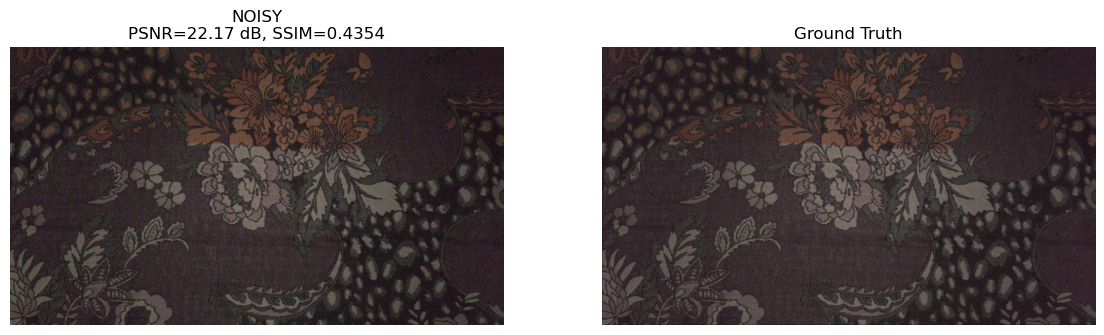

In [24]:
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity


# 1. 随机选择一张 NOISY
random_noisy = random.choice(noisy_files)

# 2. 找到对应 GT
gt_name = random_noisy.name.replace(
    "_NOISY_SRGB_",
    "_GT_SRGB_"
)

random_gt = random_noisy.parent / gt_name


# 3. 读取图片
noisy_img = Image.open(random_noisy).convert("RGB")
gt_img = Image.open(random_gt).convert("RGB")

noisy_array = np.array(noisy_img)
gt_array = np.array(gt_img)


# 4. 计算 PSNR
psnr = peak_signal_noise_ratio(
    gt_array,
    noisy_array,
    data_range=255
)

# 5. 计算 SSIM
ssim = structural_similarity(
    gt_array,
    noisy_array,
    channel_axis=2,
    data_range=255
)


# 6. 输出信息
print("NOISY：", random_noisy.name)
print("GT：", random_gt.name)
print(f"PSNR：{psnr:.4f} dB")
print(f"SSIM：{ssim:.4f}")


# 7. 并排显示
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(noisy_img)
plt.title(f"NOISY\nPSNR={psnr:.2f} dB, SSIM={ssim:.4f}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gt_img)
plt.title("Ground Truth")
plt.axis("off")

plt.show()